In [1]:
import pandas as pd
import numpy as np

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
print("Participants:", df["subject_id"].nunique())

display(df.head())

Saving multi_subject_features.csv to multi_subject_features.csv
Dataset shape: (16688, 36)
Participants: 6


,EEG Fpz-Cz_mean,EEG Fpz-Cz_std,EEG Fpz-Cz_rms,EEG Fpz-Cz_hjorth_activity,EEG Fpz-Cz_hjorth_mobility,EEG Fpz-Cz_hjorth_complexity,EEG Fpz-Cz_delta_power,EEG Fpz-Cz_delta_relative_power,EEG Fpz-Cz_theta_power,EEG Fpz-Cz_theta_relative_power,...,EEG Pz-Oz_alpha_power,EEG Pz-Oz_alpha_relative_power,EEG Pz-Oz_sigma_power,EEG Pz-Oz_sigma_relative_power,EEG Pz-Oz_beta_power,EEG Pz-Oz_beta_relative_power,sleep_stage,subject_id,recording_id,epoch_index
0,7.677320e-08,0.000036,0.000036,1.299930e-09,0.200366,6.108692,6.835205e-10,0.853724,9.437714e-11,0.117878,...,3.253217e-12,0.089687,2.094702e-12,0.057749,2.863771e-12,0.078951,W,SC4001,SC4001E0,0
1,-6.469066e-07,0.000026,0.000026,6.654303e-10,0.393699,3.664441,4.029480e-10,0.810147,4.376367e-11,0.087989,...,7.241140e-12,0.132479,6.031485e-12,0.110348,1.528662e-11,0.279674,W,SC4001,SC4001E0,1
2,8.259596e-07,0.000031,0.000031,9.699986e-10,0.258863,5.597541,5.225989e-10,0.899825,2.271802e-11,0.039117,...,3.089535e-11,0.508558,2.902779e-12,0.047782,4.482796e-12,0.073790,W,SC4001,SC4001E0,2
3,-5.141783e-07,0.000018,0.000018,3.073842e-10,0.316290,4.090785,1.886731e-10,0.813741,2.051944e-11,0.088500,...,4.730373e-11,0.563190,1.973719e-12,0.023499,3.963850e-12,0.047193,W,SC4001,SC4001E0,3
4,-1.102670e-07,0.000017,0.000017,2.838617e-10,0.340875,3.508630,1.836531e-10,0.752217,4.068264e-11,0.166630,...,3.964185e-11,0.444802,2.576586e-12,0.028911,4.032750e-12,0.045250,W,SC4001,SC4001E0,4


In [2]:
metadata_columns = [
    "sleep_stage",
    "subject_id",
    "recording_id",
    "epoch_index"
]

feature_columns = [
    col for col in df.columns
    if col not in metadata_columns
]

X = df[feature_columns].astype(float)
y = df["sleep_stage"]
groups = df["subject_id"]

print("Features:", X.shape[1])
print("Samples:", X.shape[0])
print("Participants:", groups.nunique())

Features: 32
Samples: 16688
Participants: 6


In [3]:
print("Missing values:", X.isnull().sum().sum())
print("Infinite values:", np.isinf(X.to_numpy()).sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nClass distribution:")
print(y.value_counts())

Missing values: 0
Infinite values: 0
Duplicate rows: 0

Class distribution:
sleep_stage
W      11340
N2      2792
REM     1028
N3       932
N1       596
Name: count, dtype: int64


In [4]:
#Split participants
from sklearn.model_selection import GroupKFold

all_subjects = sorted(groups.unique())

test_subjects = ["SC4021", "SC4022"]
development_subjects = [
    s for s in all_subjects if s not in test_subjects
]

dev_mask = groups.isin(development_subjects)
test_mask = groups.isin(test_subjects)

X_dev = X.loc[dev_mask]
y_dev = y.loc[dev_mask]
groups_dev = groups.loc[dev_mask]

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]
groups_test = groups.loc[test_mask]

print("Development participants:", development_subjects)
print("Final test participants:", test_subjects)

print("\nDevelopment samples:", len(X_dev))
print("Test samples:", len(X_test))

Development participants: ['SC4001', 'SC4002', 'SC4011', 'SC4012']
Final test participants: ['SC4021', 'SC4022']

Development samples: 11129
Test samples: 5559


In [5]:
#Check class distribution by participant
print("Development distribution:")
display(
    pd.crosstab(groups_dev, y_dev)
)

print("\nFinal test distribution:")
display(
    pd.crosstab(groups_test, y_test)
)

Development distribution:


sleep_stage,N1,N2,N3,REM,W
subject_id,,,,,
SC4001,58,250,220,125,1997
SC4002,59,373,297,215,1885
SC4011,109,562,105,170,1856
SC4012,92,660,96,176,1824



Final test distribution:


sleep_stage,N1,N2,N3,REM,W
subject_id,,,,,
SC4021,94,545,95,163,1907
SC4022,184,402,119,179,1871


In [6]:
#Configure the search
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GroupKFold, RandomizedSearchCV

from scipy.stats import loguniform

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        class_weight="balanced"
    ))
])

parameter_distributions = {
    "classifier__C": loguniform(0.1, 100),
    "classifier__gamma": loguniform(0.0001, 1)
}

group_cv = GroupKFold(n_splits=4)

print("SVM pipeline configured.")
print("Cross-validation folds:", group_cv.get_n_splits())

SVM pipeline configured.
Cross-validation folds: 4


In [7]:
#Run hyperparameter tuning
search = RandomizedSearchCV(
    estimator=svm_pipeline,
    param_distributions=parameter_distributions,
    n_iter=12,
    scoring="f1_macro",
    cv=group_cv,
    random_state=42,
    n_jobs=1,
    verbose=2,
    refit=True
)

search.fit(
    X_dev,
    y_dev,
    groups=groups_dev
)

print("\nTuning completed.")
print("Best parameters:", search.best_params_)
print("Best cross-validation Macro F1:", round(search.best_score_, 4))

Fitting 4 folds for each of 12 candidates, totalling 48 fits
[CV] END classifier__C=1.3292918943162166, classifier__gamma=0.6351221010640696; total time=  17.6s
[CV] END classifier__C=1.3292918943162166, classifier__gamma=0.6351221010640696; total time=  13.2s
[CV] END classifier__C=1.3292918943162166, classifier__gamma=0.6351221010640696; total time=  11.3s
[CV] END classifier__C=1.3292918943162166, classifier__gamma=0.6351221010640696; total time=  12.2s
[CV] END classifier__C=15.702970884055382, classifier__gamma=0.024810409748678097; total time=   0.7s
[CV] END classifier__C=15.702970884055382, classifier__gamma=0.024810409748678097; total time=   0.7s
[CV] END classifier__C=15.702970884055382, classifier__gamma=0.024810409748678097; total time=   1.1s
[CV] END classifier__C=15.702970884055382, classifier__gamma=0.024810409748678097; total time=   1.5s
[CV] END classifier__C=0.2938027938703535, classifier__gamma=0.0004207053950287938; total time=   5.7s
[CV] END classifier__C=0.293

In [8]:
#Inspect the tuning results
tuning_results = pd.DataFrame(search.cv_results_)

tuning_results = tuning_results[
    [
        "param_classifier__C",
        "param_classifier__gamma",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].sort_values("rank_test_score")

display(tuning_results.round(4))

,param_classifier__C,param_classifier__gamma,mean_test_score,std_test_score,rank_test_score
1,15.7030,0.0248,0.7499,0.0662,1
8,0.8179,0.0126,0.7491,0.0663,2
6,31.4288,0.0007,0.7405,0.0731,3
4,6.3584,0.0680,0.7376,0.0756,4
9,1.9762,0.0015,0.7119,0.0669,5
11,0.7524,0.0029,0.7076,0.0645,6
10,6.8479,0.0004,0.7070,0.0649,7
7,0.3511,0.0005,0.6364,0.0270,8
2,0.2938,0.0004,0.6259,0.0317,9
3,0.1494,0.2915,0.5889,0.1479,10


In [9]:
#Evaluate tuned SVM
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    cohen_kappa_score,
    classification_report,
    confusion_matrix
)

# Use the best model selected through development-set CV
best_svm = search.best_estimator_

# Predict on untouched test participants
y_test_pred = best_svm.predict(X_test)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_balanced_accuracy = balanced_accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(y_test, y_test_pred, average="macro")
test_kappa = cohen_kappa_score(y_test, y_test_pred)

print("TUNED SVM - FINAL TEST RESULTS")
print("-" * 40)

print(f"Accuracy:          {test_accuracy:.4f}")
print(f"Balanced Accuracy: {test_balanced_accuracy:.4f}")
print(f"Macro F1:          {test_macro_f1:.4f}")
print(f"Cohen Kappa:       {test_kappa:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_test_pred,
    labels=["W", "N1", "N2", "N3", "REM"]
))

TUNED SVM - FINAL TEST RESULTS
----------------------------------------
Accuracy:          0.9032
Balanced Accuracy: 0.7195
Macro F1:          0.7153
Cohen Kappa:       0.8084

Classification Report:
              precision    recall  f1-score   support

          N1       0.32      0.23      0.27       278
          N2       0.82      0.89      0.86       947
          N3       0.78      0.61      0.68       214
         REM       0.71      0.89      0.79       342
           W       0.99      0.97      0.98      3778

    accuracy                           0.90      5559
   macro avg       0.72      0.72      0.72      5559
weighted avg       0.90      0.90      0.90      5559


Confusion Matrix:
[[3675   87   13    0    3]
 [  34   65   86    0   93]
 [   2   35  847   36   27]
 [   8    3   73  130    0]
 [   7   16   14    1  304]]


In [10]:
#Same-split model comparison.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    cohen_kappa_score
)
import pandas as pd

# Baseline SVM
baseline_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        random_state=42
    ))
])

# Baseline Random Forest
baseline_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

models = {
    "Baseline SVM": baseline_svm,
    "Tuned SVM": best_svm,
    "Random Forest": baseline_rf
}

comparison_results = []
test_predictions = {}

for model_name, model in models.items():

    # Train only on development participants
    model.fit(X_dev, y_dev)

    # Evaluate on the same untouched test participants
    predictions = model.predict(X_test)
    test_predictions[model_name] = predictions

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Macro F1": f1_score(y_test, predictions, average="macro"),
        "Cohen Kappa": cohen_kappa_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df
    .sort_values("Macro F1", ascending=False)
    .round(4)
)

,Model,Accuracy,Balanced Accuracy,Macro F1,Cohen Kappa
0,Baseline SVM,0.8894,0.7609,0.7272,0.7870
1,Tuned SVM,0.9032,0.7195,0.7153,0.8084
2,Random Forest,0.9007,0.6854,0.6897,0.8002


In [11]:
#Per-stage model comparison.
from sklearn.metrics import classification_report
import pandas as pd

stage_results = []

for model_name, predictions in test_predictions.items():

    report = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )

    for stage in ["W", "N1", "N2", "N3", "REM"]:
        stage_results.append({
            "Model": model_name,
            "Sleep Stage": stage,
            "Precision": report[stage]["precision"],
            "Recall": report[stage]["recall"],
            "F1 Score": report[stage]["f1-score"]
        })

stage_comparison = pd.DataFrame(stage_results)

display(stage_comparison.round(4))

,Model,Sleep Stage,Precision,Recall,F1 Score
0,Baseline SVM,W,0.9879,0.9489,0.9680
1,Baseline SVM,N1,0.2537,0.3058,0.2773
2,Baseline SVM,N2,0.8962,0.8384,0.8663
3,Baseline SVM,N3,0.7303,0.8224,0.7736
4,Baseline SVM,REM,0.6496,0.8889,0.7506
5,Tuned SVM,W,0.9863,0.9727,0.9795
6,Tuned SVM,N1,0.3155,0.2338,0.2686
7,Tuned SVM,N2,0.8199,0.8944,0.8556
8,Tuned SVM,N3,0.7784,0.6075,0.6824
9,Tuned SVM,REM,0.7119,0.8889,0.7906


In [12]:
#Permutation feature importance
from sklearn.inspection import permutation_importance
import pandas as pd

# Calculate permutation importance on the final test set
importance = permutation_importance(
    baseline_svm,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

# Create importance table
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": importance.importances_mean,
    "Importance Std": importance.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance Mean",
    ascending=False
).reset_index(drop=True)

print("TOP 15 EEG FEATURES")
display(importance_df.head(15).round(5))

TOP 15 EEG FEATURES


,Feature,Importance Mean,Importance Std
0,EEG Pz-Oz_hjorth_mobility,0.12133,0.00752
1,EEG Fpz-Cz_hjorth_complexity,0.07618,0.00478
2,EEG Pz-Oz_delta_power,0.06719,0.00559
3,EEG Pz-Oz_beta_relative_power,0.05902,0.00671
4,EEG Pz-Oz_delta_relative_power,0.05548,0.00772
5,EEG Pz-Oz_alpha_relative_power,0.04210,0.00552
6,EEG Fpz-Cz_theta_relative_power,0.04149,0.00156
7,EEG Fpz-Cz_sigma_relative_power,0.04128,0.00365
8,EEG Pz-Oz_beta_power,0.04070,0.00680
9,EEG Fpz-Cz_delta_relative_power,0.03210,0.00225


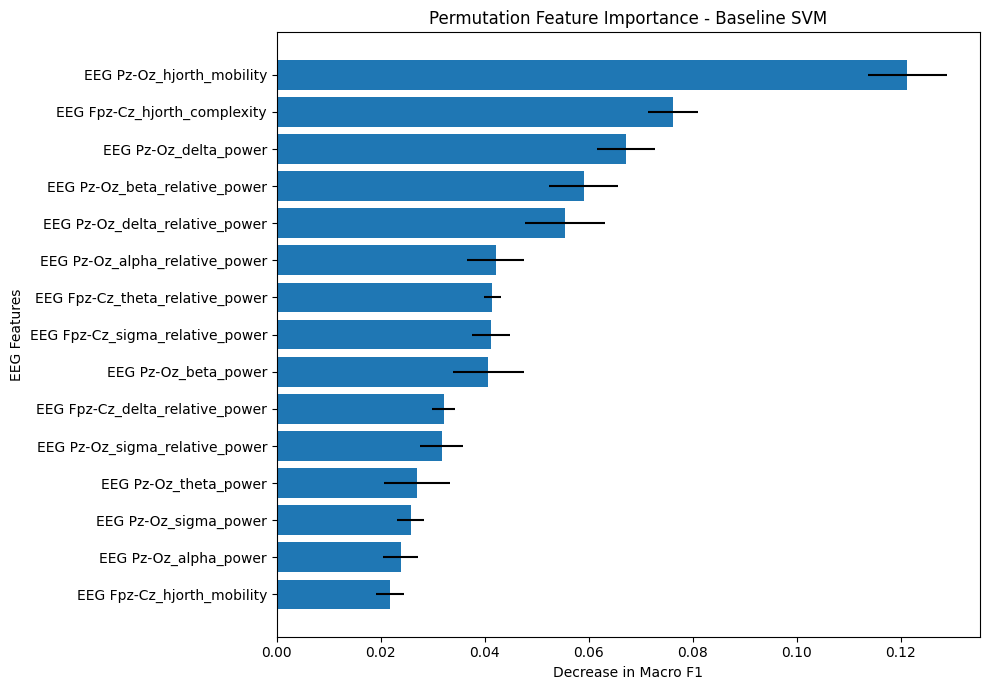

In [13]:
#Visualize the top 15 features
import matplotlib.pyplot as plt

top_features = importance_df.head(15).sort_values(
    "Importance Mean"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance Mean"],
    xerr=top_features["Importance Std"]
)

plt.xlabel("Decrease in Macro F1")
plt.ylabel("EEG Features")
plt.title("Permutation Feature Importance - Baseline SVM")
plt.tight_layout()
plt.show()

In [14]:
import os

final_dir = "/content/sleepsense/final_outputs"

os.makedirs(final_dir, exist_ok=True)

print("Final output directory created:", final_dir)

Final output directory created: /content/sleepsense/final_outputs


In [15]:
import joblib

final_model_package = {
    "model": baseline_svm,
    "feature_columns": list(X_dev.columns),
    "classes": list(baseline_svm.classes_),
    "model_name": "Baseline SVM",
    "kernel": "RBF",
    "C": 1.0,
    "gamma": "scale"
}

joblib.dump(
    final_model_package,
    f"{final_dir}/sleepsense_final_model.pkl"
)

print("Selected baseline SVM saved successfully.")

Selected baseline SVM saved successfully.


In [16]:
# Save model comparison
comparison_df.to_csv(
    f"{final_dir}/model_comparison.csv",
    index=False
)

# Save feature importance
importance_df.to_csv(
    f"{final_dir}/feature_importance.csv",
    index=False
)

# Save final test predictions
final_predictions = pd.DataFrame({
    "subject_id": groups_test.values,
    "actual_stage": y_test.values,
    "predicted_stage": test_predictions["Baseline SVM"]
})

final_predictions.to_csv(
    f"{final_dir}/final_test_predictions.csv",
    index=False
)

# Save stage-wise metrics
stage_comparison.to_csv(
    f"{final_dir}/stage_wise_comparison.csv",
    index=False
)

print("Evaluation files saved successfully.")

Evaluation files saved successfully.


In [17]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/SleepSense_Final_Outputs",
    "zip",
    final_dir
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>